# 01 · Game engine

Sanity checks for the Numba 2048 engine in `src/game/engine.py`: pretty-printed boards,
the four moves, a full random game, and a random-play benchmark.

In [1]:
%load_ext autoreload
%autoreload 2

import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from game import engine as E

assert platform.machine() == "arm64", f"not native arm64 Python: {platform.machine()}"
print(platform.python_version(), platform.machine())

Matplotlib is building the font cache; this may take a moment.


3.12.15 arm64


## Boards and moves

Boards are a single `uint64`, tiles are exponents. `from_values` / `format_board` convert
to and from real tile values. Each move returns the **afterstate** (slide only, no spawn)
and the merge score.

In [2]:
board = E.from_values([
    [2, 2, 2, 2],
    [4, 4, 8, 0],
    [2, 0, 0, 2],
    [0, 4, 0, 0],
])
print(f"board = {board:#018x}")
print(E.format_board(board))
print("legal:", dict(zip(E.ACTION_NAMES, E.legal_moves(board).tolist())))

board = 0x0020100103221111
+------+------+------+------+
|  2   |  2   |  2   |  2   |
+------+------+------+------+
|  4   |  4   |  8   |  .   |
+------+------+------+------+
|  2   |  .   |  .   |  2   |
+------+------+------+------+
|  .   |  4   |  .   |  .   |
+------+------+------+------+
legal: {'up': True, 'right': True, 'down': True, 'left': True}


In [3]:
for a in range(4):
    after, reward = E.move(board, a)
    print(f"{E.ACTION_NAMES[a]:>5}   reward {reward}")
    print(E.format_board(after))

   up   reward 12
+------+------+------+------+
|  2   |  2   |  2   |  4   |
+------+------+------+------+
|  4   |  8   |  8   |  .   |
+------+------+------+------+
|  2   |  .   |  .   |  .   |
+------+------+------+------+
|  .   |  .   |  .   |  .   |
+------+------+------+------+
right   reward 20
+------+------+------+------+
|  .   |  .   |  4   |  4   |
+------+------+------+------+
|  .   |  .   |  8   |  8   |
+------+------+------+------+
|  .   |  .   |  .   |  4   |
+------+------+------+------+
|  .   |  .   |  .   |  4   |
+------+------+------+------+
 down   reward 12
+------+------+------+------+
|  .   |  .   |  .   |  .   |
+------+------+------+------+
|  2   |  .   |  .   |  .   |
+------+------+------+------+
|  4   |  2   |  2   |  .   |
+------+------+------+------+
|  2   |  8   |  8   |  4   |
+------+------+------+------+
 left   reward 20
+------+------+------+------+
|  4   |  4   |  .   |  .   |
+------+------+------+------+
|  8   |  8   |  .   |  .   

## Stepping through a seeded game

Each step: choose a move → afterstate → spawn a 2 or 4. Same seed, same game.

In [4]:
rng = E.make_rng(2048)
board = E.new_game(rng)
print("start")
print(E.format_board(board))

for a in [E.LEFT, E.UP, E.RIGHT]:
    after, reward = E.move(board, a)
    board = E.spawn_tile(after, rng)
    print(f"\n{E.ACTION_NAMES[a]}  (reward {reward})")
    for a_line, b_line in zip(E.format_board(after).splitlines(), E.format_board(board).splitlines()):
        print(a_line, "  ", b_line)
print("\n(left: afterstate, right: after spawn)")

start
+------+------+------+------+
|  4   |  .   |  .   |  .   |
+------+------+------+------+
|  .   |  .   |  .   |  .   |
+------+------+------+------+
|  .   |  2   |  .   |  .   |
+------+------+------+------+
|  .   |  .   |  .   |  .   |
+------+------+------+------+

left  (reward 0)
+------+------+------+------+    +------+------+------+------+
|  4   |  .   |  .   |  .   |    |  4   |  .   |  .   |  .   |
+------+------+------+------+    +------+------+------+------+
|  .   |  .   |  .   |  .   |    |  .   |  .   |  .   |  2   |
+------+------+------+------+    +------+------+------+------+
|  2   |  .   |  .   |  .   |    |  2   |  .   |  .   |  .   |
+------+------+------+------+    +------+------+------+------+
|  .   |  .   |  .   |  .   |    |  .   |  .   |  .   |  .   |
+------+------+------+------+    +------+------+------+------+

up  (reward 0)
+------+------+------+------+    +------+------+------+------+
|  4   |  .   |  .   |  2   |    |  4   |  .   |  2   |  2  

## A full random game

In [5]:
rng = E.make_rng(7)
board = E.new_game(rng)
score = n_moves = 0
while not E.is_game_over(board):
    legal = np.flatnonzero(E.legal_moves(board))
    a = int(legal[E.rng_below(rng, len(legal))])
    after, reward = E.move(board, a)
    board = E.spawn_tile(after, rng)
    score += reward
    n_moves += 1

print(E.format_board(board))
print(f"score {score}, moves {n_moves}, max tile {1 << E.max_tile(board)}")

+------+------+------+------+
|  16  |  8   |  2   |  4   |
+------+------+------+------+
|  8   |  64  |  4   |  16  |
+------+------+------+------+
|  4   | 128  |  8   |  2   |
+------+------+------+------+
|  2   |  4   |  2   |  4   |
+------+------+------+------+
score 1204, moves 124, max tile 128


## Benchmark: random moves per second

`play_random_games` runs the whole loop in Numba (legal-move check, move, spawn, RNG).
The first call is a warm-up so compile/cache-load time is not measured.

In [6]:
E.play_random_games(0, 10)  # warm-up

n_games = 20_000
t0 = time.perf_counter()
scores, max_tiles, moves = E.play_random_games(1, n_games)
dt = time.perf_counter() - t0

print(f"{n_games:,} games, {moves.sum():,} moves in {dt:.2f} s")
print(f"{moves.sum() / dt / 1e6:.2f} M moves/s   {n_games / dt:,.0f} games/s   (single core)")

20,000 games, 2,369,871 moves in 0.06 s
36.60 M moves/s   308,837 games/s   (single core)


In [7]:
# the same game loop driven from Python, calling the jitted functions one by one:
# shows why hot loops (training, expectimax) must stay inside Numba
rng = E.make_rng(1)
n_moves, t0 = 0, time.perf_counter()
for _ in range(200):
    board = E.new_game(rng)
    while not E.is_game_over(board):
        legal = np.flatnonzero(E.legal_moves(board))
        board = E.spawn_tile(E.afterstate(board, int(legal[E.rng_below(rng, len(legal))])), rng)
        n_moves += 1
dt_py = time.perf_counter() - t0
print(f"Python-driven loop: {n_moves / dt_py / 1e6:.3f} M moves/s "
      f"({moves.sum() / dt / (n_moves / dt_py):.0f}x slower than all-Numba)")

Python-driven loop: 0.711 M moves/s (51x slower than all-Numba)


## Random play statistics

,score,max_tile,moves
count,20000.0,20000.0,20000.0
mean,1096.5,107.3,118.5
std,538.4,55.6,37.9
min,60.0,8.0,26.0
25%,672.0,64.0,90.0
50%,1052.0,128.0,115.0
75%,1360.0,128.0,141.0
max,5036.0,512.0,341.0


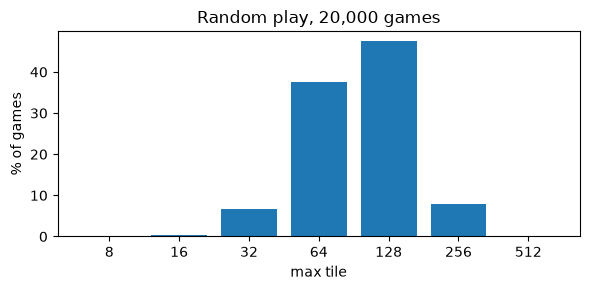

In [8]:
df = pd.DataFrame({"score": scores, "max_tile": 1 << max_tiles, "moves": moves})
display(df.describe().round(1))

counts = df["max_tile"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar([str(t) for t in counts.index], counts.values / n_games * 100)
ax.set_xlabel("max tile")
ax.set_ylabel("% of games")
ax.set_title(f"Random play, {n_games:,} games")
plt.tight_layout()
plt.show()